# Bank Marketing — Dự đoán đăng ký tiền gửi có kỳ hạn 
## Cấu trúc notebook

| Phần | Nội dung |
|---|---|
| 1 | Thư viện và cấu hình |
| 2 | Đọc dữ liệu, kiểm tra cấu trúc thời gian |
| 3 | Chia train / test theo thời gian (3.1: chẩn đoán concept drift) |
| 4 | Feature engineering (không phụ thuộc dữ liệu) |
| 5 | Chọn cấu hình đặc trưng bằng CV thời gian (5.4: kiểm tra cách điền `pdays_log`) |
| 6 | **Mô hình baseline: Logistic Regression đơn giản** |
| 7 | Tối ưu tham số bằng Optuna (LR, RF thường / Balanced RF, XGBoost) |
| 8 | CV thời gian, chọn ngưỡng, huấn luyện lại |
| 9 | Kết quả trên test set: **bảng chính theo khối thời gian**, 9.1 bootstrap |
| 10 | Kiểm tra overfitting |
| 11 – 12 | Biểu đồ, feature importance |
| 13 | Mô phỏng vận hành: cập nhật ngưỡng, **huấn luyện lại định kỳ (quy trình khuyến nghị)**; 13.2b cập nhật ngưỡng sau huấn luyện lại |
| 14 | So sánh với cách làm cũ (ablation) |
| 15 | Phụ lục: ảnh hưởng của `duration` |
| 16 | Kiểm tra rò rỉ và kết luận |

## 1. Thư viện và cấu hình

### 1.1 Cài đặt thư viện
Kiểm tra `optuna`, `xgboost` và `imbalanced-learn`; thư viện nào chưa có thì tự cài bằng `pip`.

In [1]:
import importlib.util, subprocess, sys
for mod, pkg in [('optuna', 'optuna'), ('xgboost', 'xgboost'), ('imblearn', 'imbalanced-learn')]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

### 1.2 Import và tham số cấu hình
Import thư viện và khai báo các tham số điều khiển toàn bộ notebook:

| Tham số | Ý nghĩa |
|---|---|
| `N_TRIALS` | Số trial Optuna cho mỗi mô hình (mục 7) |
| `N_TRIALS_OLD` | Số trial cho phần so sánh với cách làm cũ (mục 14) |
| `N_SPLITS` | Số fold của `TimeSeriesSplit` |
| `ADD_AGE_GROUP` | Thêm đặc trưng nhóm tuổi `age_group` |
| `ADD_CONTACT_INTENSITY` | Thêm `contact_intensity` (`campaign + previous`); đang tắt |
| `DROP_CAMPAIGN` | Bỏ `campaign_log` vì `campaign` chỉ biết đầy đủ sau cuộc gọi |
| `PDAYS_FILL` | Giá trị điền cho `pdays_log` khi khách chưa từng liên hệ (chỉ LR/RF; XGBoost dùng NaN gốc) |
| `TEST_FRAC` | Tỷ lệ các dòng cuối dùng làm test (20%) |
| `DATA_PATH` | Đường dẫn file dữ liệu đã làm sạch |

`tscv` là `TimeSeriesSplit` kiểu expanding window. `FOLD_W` là trọng số các fold tăng dần và có tổng bằng 1, nên fold càng gần hiện tại càng nặng khi tính ROC-AUC có trọng số.

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, precision_recall_curve, roc_curve)
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

RANDOM_STATE = 42
N_TRIALS     = 40      # số trial Optuna mỗi mô hình
N_TRIALS_OLD = 15      # số trial cho phần so sánh với cách làm cũ (mục 14)
N_SPLITS     = 5
ADD_AGE_GROUP         = True   # thêm nhóm tuổi (mục 4)
ADD_CONTACT_INTENSITY = False  # campaign + previous: mục 5.2 cho thấy không cải thiện và thừa hưởng rủi ro rò rỉ của `campaign`
DROP_CAMPAIGN         = True   # bỏ campaign_log: chỉ biết đầy đủ sau cuộc gọi, bỏ đi không mất điểm ở mục 5.2
PDAYS_FILL            = 0.0    # giá trị điền cho pdays_log khi chưa từng liên hệ (chỉ LR/RF; XGBoost dùng NaN gốc); xem mục 5.4
TEST_FRAC    = 0.2
DATA_PATH    = 'bank_data_cleaned.csv'

tscv   = TimeSeriesSplit(n_splits=N_SPLITS)
# Trọng số fold tăng dần: fold càng gần hiện tại càng giống môi trường triển khai
FOLD_W = np.arange(1, N_SPLITS + 1) / (N_SPLITS * (N_SPLITS + 1) / 2)
print('Trọng số fold:', FOLD_W.round(3))

Trọng số fold: [0.067 0.133 0.2   0.267 0.333]


## 2. Đọc dữ liệu và kiểm tra cấu trúc thời gian
File gốc được sắp xếp theo thời gian gọi nhưng **không có cột ngày/năm**. Cột `month` lặp lại theo chu kỳ, nên ta chỉ dùng nó để *kiểm tra* (không đưa vào mô hình): mỗi lần tháng "quay vòng" (12 → 1) là sang năm mới.

In [3]:
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape, '| ô thiếu:', int(df.isna().sum().sum()), '| dòng trùng:', int(df.duplicated().sum()))
print('Tỷ lệ y=1 toàn bộ:', round(df['y'].mean(), 4))

MONTH_NUM = {m: i + 1 for i, m in enumerate('jan feb mar apr may jun jul aug sep oct nov dec'.split())}
m_num = df['month'].map(MONTH_NUM).to_numpy()
audit = pd.DataFrame({'block': np.arange(len(df)) // 2000,
                      'y': df['y'].to_numpy(),
                      'da_lien_he_truoc': (df['pdays'] != -1).astype(int).to_numpy(),
                      'nam_idx': np.cumsum(np.r_[0, (np.diff(m_num) < 0).astype(int)])})
by_block = audit.groupby('block').agg(ty_le_y1=('y', 'mean'), ty_le_da_lien_he=('da_lien_he_truoc', 'mean'))
print('Số "năm" suy ra từ chu kỳ tháng:', audit['nam_idx'].nunique())

Shape: (45208, 17) | ô thiếu: 0 | dòng trùng: 0
Tỷ lệ y=1 toàn bộ: 0.117
Số "năm" suy ra từ chu kỳ tháng: 3


### 2.1 Biểu đồ dữ liệu trôi theo thời gian
Chia dữ liệu thành các khối 2.000 dòng liên tiếp rồi vẽ tỷ lệ `y=1` và tỷ lệ khách đã được liên hệ trước (`pdays != -1`) theo vị trí dòng. Đường nét đứt đánh dấu điểm cắt giữa train và test.

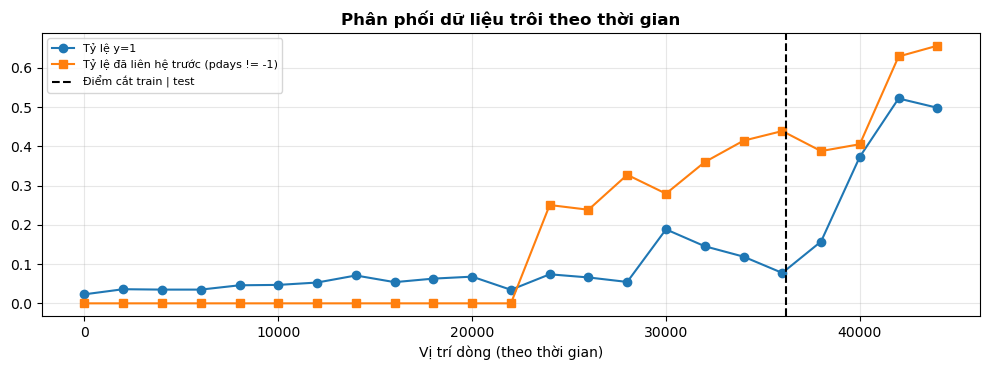

In [4]:
n_train = int(len(df) * (1 - TEST_FRAC))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(by_block.index * 2000, by_block['ty_le_y1'], marker='o', label='Tỷ lệ y=1')
ax.plot(by_block.index * 2000, by_block['ty_le_da_lien_he'], marker='s', label='Tỷ lệ đã liên hệ trước (pdays != -1)')
ax.axvline(n_train, color='k', ls='--', label='Điểm cắt train | test')
ax.set_xlabel('Vị trí dòng (theo thời gian)'); ax.set_title('Phân phối dữ liệu trôi theo thời gian', fontweight='bold')
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

Nhận xét: khoảng 20.000 dòng đầu **hoàn toàn không có** khách hàng từng được liên hệ trước (`pdays = -1`), còn tỷ lệ `y=1` tăng vọt ở phần cuối. Đây là *covariate shift* và *prior shift* thật sự trong dữ liệu, nên mọi bước tuning/ngưỡng phải mô phỏng đúng bài toán "học từ quá khứ, dự báo tương lai".

## 3. Chia train / test theo thời gian — làm trước mọi bước khác
Test set (20% dòng cuối) **không** được dùng để tuning, chọn đặc trưng, chọn ngưỡng hay chọn mô hình.

In [5]:
y_all = df['y']
train_df, test_df = df.iloc[:n_train].copy(), df.iloc[n_train:].copy()
y_train, y_test = train_df['y'], test_df['y']
assert train_df.index.max() < test_df.index.min(), 'Train phải đứng trước test theo thời gian'
print(f'Train: {len(train_df)} dòng (0 → {n_train - 1}) | Test: {len(test_df)} dòng ({n_train} → {len(df) - 1})')
print('Tỷ lệ y=1 — train:', round(y_train.mean(), 4), '| test:', round(y_test.mean(), 4))
print('Tỷ lệ đã liên hệ trước — train:', round((train_df.pdays != -1).mean(), 3),
      '| test:', round((test_df.pdays != -1).mean(), 3))
print('Tỷ lệ y=1 trong từng fold validation của TimeSeriesSplit (train):',
      [round(y_train.iloc[va].mean(), 3) for _, va in tscv.split(train_df)])

Train: 36166 dòng (0 → 36165) | Test: 9042 dòng (36166 → 45207)
Tỷ lệ y=1 — train: 0.0673 | test: 0.3159
Tỷ lệ đã liên hệ trước — train: 0.106 | test: 0.491
Tỷ lệ y=1 trong từng fold validation của TimeSeriesSplit (train): [0.042, 0.061, 0.061, 0.058, 0.15]


### 3.1 Chẩn đoán concept drift (chỉ để hiểu dữ liệu)
Với mỗi đặc trưng, tính **ROC-AUC đơn biến** theo từng khối thời gian: 5 khối của tập train và khối TEST. Cách đọc:
- AUC > 0,5: giá trị lớn đi cùng `y=1`; AUC < 0,5: đi cùng `y=0`; AUC ≈ 0,5: không có thông tin.
- Nếu cùng một đặc trưng đổi phía của 0,5 giữa các khối (đặc biệt từ khối train cuối sang TEST) thì quan hệ với `y` đã **đảo chiều**: đây là *concept drift*. Mô hình học từ quá khứ không thể biết trước điều này, nên không có bước tuning hợp lệ nào sửa được nó.

Cột TEST chỉ dùng để giải thích vì sao điểm trên test thấp hơn nhiều so với CV ngẫu nhiên; nó không tham gia bất kỳ quyết định nào của pipeline.

In [6]:
def drift_table(d, n_blocks=5):
    F = pd.DataFrame(index=d.index)
    F['age'], F['balance'] = d['age'], d['balance']
    F['housing=yes'], F['loan=yes'] = (d['housing'] == 'yes').astype(int), (d['loan'] == 'yes').astype(int)
    F['da_lien_he_truoc'], F['previous'] = (d['pdays'] != -1).astype(int), d['previous']
    for v in sorted(d['poutcome'].unique()):
        F[f'poutcome={v}'] = (d['poutcome'] == v).astype(int)
    F['contact=cellular'] = (d['contact'] == 'cellular').astype(int)
    edges = np.linspace(0, n_train, n_blocks + 1).astype(int)
    blocks = list(zip(edges[:-1], edges[1:])) + [(n_train, len(d))]
    labels = [f'Train {i + 1}' for i in range(n_blocks)] + ['TEST']
    out = {}
    for col in F:
        r = []
        for a, b in blocks:
            x, yy = F[col].iloc[a:b], d['y'].iloc[a:b]
            r.append(roc_auc_score(yy, x) if x.nunique() > 1 and yy.nunique() > 1 else np.nan)
        out[col] = r
    res = pd.DataFrame(out, index=labels).T
    res.loc['(tỷ lệ y=1 của khối)'] = [d['y'].iloc[a:b].mean() for a, b in blocks]
    return res

display(drift_table(df).round(3))

,Train 1,Train 2,Train 3,Train 4,Train 5,TEST
age,0.463,0.418,0.468,0.480,0.498,0.533
balance,0.572,0.499,0.531,0.593,0.580,0.577
housing=yes,0.517,0.528,0.481,0.500,0.353,0.355
loan=yes,0.491,0.506,0.476,0.488,0.464,0.475
da_lien_he_truoc,NaN,NaN,NaN,0.464,0.434,0.558
previous,NaN,NaN,NaN,0.464,0.433,0.563
poutcome=failure,NaN,NaN,NaN,0.460,0.431,0.442
poutcome=no_previous_contact,NaN,NaN,NaN,0.536,0.566,0.442
poutcome=other,NaN,NaN,NaN,0.501,0.475,0.489
poutcome=success,NaN,NaN,NaN,0.503,0.528,0.626


## 4. Feature engineering (không phụ thuộc dữ liệu → không thể rò rỉ)
Mọi phép biến đổi ở bước này chỉ phụ thuộc **từng dòng riêng lẻ** (log, sin/cos, ánh xạ cố định), nên áp dụng cho cả train và test không làm lộ thông tin. Các bước *học tham số từ dữ liệu* (impute, scaler, one-hot) nằm trong `Pipeline` và chỉ fit trên train của từng fold.

- Bỏ `day` (ít ý nghĩa kinh doanh) và `duration` (chỉ biết sau cuộc gọi → target leakage).
- **`pdays`**: `-1` nghĩa là "chưa từng liên hệ", không phải một con số ngày. Tách thành cờ `was_contacted_before`; `pdays_log = log1p(pdays)` và để **NaN** khi chưa liên hệ (XGBoost xử lý NaN gốc; LR/RF điền 0 và đã có cờ đi kèm). Không thay `-1` bằng `0` vì `0` mang nghĩa "vừa liên hệ hôm nay".
- Biến lệch phải (`balance`, `campaign`, `previous`): `log1p` / signed-log.
- **`age_group`**: nhóm tuổi `18-30`, `31-45`, `46-60`, `60+`. Giữ cả `age` (số) lẫn `age_group` (nhóm) để Logistic Regression bắt được quan hệ phi tuyến theo tuổi. Lưu ý `pd.cut` mặc định đóng bên phải nên khoảng đầu là (18, 30] và **loại mất khách đúng 18 tuổi** (12 dòng thành NaN); vì vậy dùng `include_lowest=True`.
- **`contact_intensity`** = `campaign + previous`: tổng số lần liên hệ trong chiến dịch hiện tại và trước đó, phản ánh mức độ "tiếp xúc" của khách với các chiến dịch marketing; lấy `log1p` vì lệch phải.
- **Lưu ý về `campaign`**: theo mô tả bộ dữ liệu, `campaign` đếm cả cuộc gọi cuối cùng, tức là chỉ biết đầy đủ *sau* khi chiến dịch kết thúc với khách đó. Nó không nghiêm trọng như `duration` nhưng vẫn là nguồn rò rỉ tiềm ẩn (khách đồng ý thì ngừng bị gọi). Mục 5.2 có một dòng kiểm tra bỏ các biến dẫn xuất từ `campaign` để đo mức phụ thuộc.
- **`month`**: 3 cách mã hóa — `none`, `cyc` (sin/cos để tháng 12 và 1 liền kề), `onehot`. Chọn bằng CV thời gian ở mục 5.
- **`contact`**: `unknown` tập trung ở giai đoạn đầu → có thể là "đại diện cho thời điểm" hơn là hành vi khách hàng; cũng được kiểm tra ở mục 5.
- `poutcome = 'unknown'` (chỉ 5 dòng, đều đã từng được liên hệ) gộp vào `other`.

### Hàm dùng chung: `build_features`, `make_pipe`, `cv_time`
- **`build_features`**: tạo ma trận đặc trưng từ dữ liệu gốc; các cờ (`month_mode`, `drop_contact`, `use_duration`, `add_age_group`, `add_contact_intensity`, `drop_campaign`) bật/tắt từng nhóm đặc trưng.
- **`make_pipe`**: ghép tiền xử lý và mô hình thành một `Pipeline`. Biến phân loại dùng one-hot (không `drop='first'`); biến số điền thiếu bằng hằng số và scale nếu `scale=True`; `native_nan=True` giữ NaN nguyên bản cho XGBoost.
- **`cv_time`**: chạy CV expanding window, trả về ROC-AUC và PR-AUC từng fold, ROC-AUC và PR-AUC có trọng số (`FOLD_W`), và xác suất out-of-fold (NaN ở phần train đầu tiên chưa được dự đoán).

In [7]:
AGE_BINS   = [18, 30, 45, 60, np.inf]
AGE_LABELS = ['18-30', '31-45', '46-60', '60+']

def build_features(d, month_mode='none', drop_contact=False, use_duration=False,
                   add_age_group=True, add_contact_intensity=True, drop_campaign=False):
    X = pd.DataFrame(index=d.index)
    X['age']          = d['age']
    X['balance_slog'] = np.sign(d['balance']) * np.log1p(d['balance'].abs())
    if not drop_campaign:
        X['campaign_log'] = np.log1p(d['campaign'])
    X['previous_log'] = np.log1p(d['previous'])
    X['pdays_log']    = np.where(d['pdays'] == -1, np.nan, np.log1p(d['pdays'].clip(lower=0)))
    X['was_contacted_before'] = (d['pdays'] != -1).astype(int)
    for c in ['default', 'housing', 'loan']:
        X[c] = d[c].map({'yes': 1, 'no': 0})
    if add_age_group:
        X['age_group'] = pd.cut(d['age'], bins=AGE_BINS, labels=AGE_LABELS, include_lowest=True).astype(object)
        assert X['age_group'].notna().all(), 'Có tuổi nằm ngoài các nhóm age_group'
    if add_contact_intensity:
        X['contact_intensity_log'] = np.log1p(d['campaign'] + d['previous'])
    if use_duration:
        X['duration_log'] = np.log1p(d['duration'])
    if month_mode == 'cyc':
        mm = d['month'].map(MONTH_NUM)
        X['month_sin'], X['month_cos'] = np.sin(2 * np.pi * mm / 12), np.cos(2 * np.pi * mm / 12)
    elif month_mode == 'onehot':
        X['month'] = d['month']
    for c in ['job', 'marital', 'education'] + ([] if drop_contact else ['contact']):
        X[c] = d[c]
    X['poutcome'] = d['poutcome'].replace({'unknown': 'other'})
    return X

CAT_CANDIDATES = ['job', 'marital', 'education', 'contact', 'month', 'poutcome', 'age_group']

def make_pipe(X, model, scale=False, native_nan=False, fill_value=None):
    fv = PDAYS_FILL if fill_value is None else fill_value
    cat = [c for c in CAT_CANDIDATES if c in X.columns]
    num = [c for c in X.columns if c not in cat]
    # Không dùng drop='first': nhóm lạ lúc test = toàn số 0 (không có thông tin), không bị nhầm thành nhóm cơ sở
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    if native_nan:
        num_t = 'passthrough'
    else:
        steps = [('imp', SimpleImputer(strategy='constant', fill_value=fv))]
        if scale:
            steps.append(('sc', StandardScaler()))
        num_t = Pipeline(steps)
    pre = ColumnTransformer([('cat', ohe, cat), ('num', num_t, num)], verbose_feature_names_out=False)
    return Pipeline([('pre', pre), ('model', model)])

def cv_time(pipe, X, y):
    # Expanding-window CV. Trả về AUC/AP từng fold, AUC có trọng số, và xác suất out-of-fold (NaN ở phần train-only đầu tiên)
    aucs, aps, oof = [], [], np.full(len(y), np.nan)
    for tr, va in tscv.split(X):
        m = clone(pipe).fit(X.iloc[tr], y.iloc[tr])
        p = m.predict_proba(X.iloc[va])[:, 1]
        oof[va] = p
        aucs.append(roc_auc_score(y.iloc[va], p)); aps.append(average_precision_score(y.iloc[va], p))
    return {'aucs': np.array(aucs), 'aps': np.array(aps), 'auc_w': float(np.dot(FOLD_W, aucs)),
            'ap_w': float(np.dot(FOLD_W, aps)), 'oof': oof}

## 5. Chọn cấu hình đặc trưng bằng CV thời gian (chỉ dùng tập train)
### 5.1 Cách xử lý `month` và `contact`
Dùng hai mô hình tham chiếu (Logistic Regression và XGBoost tham số vừa phải) để so sánh các cấu hình đặc trưng. Tiêu chí: ROC-AUC trung bình có trọng số trên các fold thời gian (ROC-AUC không phụ thuộc tỷ lệ lớp dương, trong khi tỷ lệ này khác nhau giữa các fold).

In [8]:
ref_lr  = lambda: LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
ref_xgb = lambda: XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                eval_metric='logloss', tree_method='hist', n_jobs=1, verbosity=0, random_state=RANDOM_STATE)
def ref_score(Xc):
    r1 = cv_time(make_pipe(Xc, ref_lr(), scale=True), Xc, y_train)
    r2 = cv_time(make_pipe(Xc, ref_xgb(), native_nan=True), Xc, y_train)
    return {'LR AUC_w': r1['auc_w'], 'XGB AUC_w': r2['auc_w'], 'Trung bình': (r1['auc_w'] + r2['auc_w']) / 2}

rows = []
for month_mode in ['none', 'cyc', 'onehot']:
    for drop_contact in [False, True]:
        Xc = build_features(train_df, month_mode, drop_contact, add_age_group=ADD_AGE_GROUP, add_contact_intensity=ADD_CONTACT_INTENSITY, drop_campaign=DROP_CAMPAIGN)
        rows.append({'month': month_mode, 'drop_contact': drop_contact, **ref_score(Xc)})
feat_cmp = pd.DataFrame(rows).sort_values('Trung bình', ascending=False).reset_index(drop=True)
display(feat_cmp.round(4))

# Quy tắc tiết kiệm: chênh lệch dưới MARGIN là nhiễu, nên chọn cấu hình ĐƠN GIẢN nhất nằm trong MARGIN so với tốt nhất
# (độ phức tạp: bỏ month < sin/cos < one-hot; bỏ contact đơn giản hơn giữ contact)
MARGIN = 0.005
cx = {'none': 0, 'cyc': 1, 'onehot': 2}
ok = feat_cmp[feat_cmp['Trung bình'] >= feat_cmp['Trung bình'].max() - MARGIN].copy()
ok['cx'] = ok['month'].map(cx) + (~ok['drop_contact']).astype(int)
BEST_CFG = ok.sort_values(['cx', 'Trung bình'], ascending=[True, False]).iloc[0]
MONTH_MODE, DROP_CONTACT = BEST_CFG['month'], bool(BEST_CFG['drop_contact'])
print(f'Cấu hình được chọn: month={MONTH_MODE}, drop_contact={DROP_CONTACT} (đơn giản nhất trong vòng {MARGIN} AUC so với tốt nhất)')

,month,drop_contact,LR AUC_w,XGB AUC_w,Trung bình
0,onehot,True,0.5879,0.5915,0.5897
1,none,True,0.5841,0.5891,0.5866
2,onehot,False,0.5786,0.5776,0.5781
3,none,False,0.5675,0.5742,0.5708
4,cyc,True,0.5598,0.5788,0.5693
5,cyc,False,0.5498,0.5701,0.5600


Cấu hình được chọn: month=none, drop_contact=True (đơn giản nhất trong vòng 0.005 AUC so với tốt nhất)


### 5.2 Đóng góp của `age_group` và `contact_intensity` (kiểm tra, không tự loại)
Giữ cấu hình `month`/`contact` đã chọn ở 5.1, so sánh CV thời gian khi thêm từng đặc trưng mới. Dòng cuối là **kiểm tra rủi ro rò rỉ**: bỏ các biến dẫn xuất từ `campaign` (`campaign_log`, `contact_intensity_log`) để xem mô hình phụ thuộc vào chúng đến đâu. Bảng này chỉ để quyết định có giữ hay không, bằng các cờ `ADD_AGE_GROUP`, `ADD_CONTACT_INTENSITY`, `DROP_CAMPAIGN` ở mục 1 (notebook không tự loại biến).

**Cách đọc:** chênh lệch dưới ~0,005 AUC là nhiễu. Nếu dòng cuối (bỏ `campaign`) xấp xỉ dòng "+ cả hai" thì bỏ `campaign` không mất gì mà loại được rủi ro rò rỉ, nên đặt `DROP_CAMPAIGN = True`. Nếu `contact_intensity` không cải thiện thì đặt `ADD_CONTACT_INTENSITY = False` (vì nó cũng chứa `campaign`).

In [9]:
variants = [('Không thêm đặc trưng mới',            dict(add_age_group=False, add_contact_intensity=False), []),
            ('+ age_group',                         dict(add_age_group=True,  add_contact_intensity=False), []),
            ('+ contact_intensity',                 dict(add_age_group=False, add_contact_intensity=True),  []),
            ('+ cả hai',                            dict(add_age_group=True,  add_contact_intensity=True),  []),
            ('+ cả hai, bỏ biến dẫn xuất campaign', dict(add_age_group=True,  add_contact_intensity=True),  ['campaign_log', 'contact_intensity_log'])]
rows = []
for label, kw, drop_cols in variants:
    Xc = build_features(train_df, MONTH_MODE, DROP_CONTACT, **kw).drop(columns=drop_cols)
    rows.append({'Biến thể': label, **ref_score(Xc)})
extra_cmp = pd.DataFrame(rows).set_index('Biến thể')
display(extra_cmp.round(4))

,LR AUC_w,XGB AUC_w,Trung bình
Biến thể,,,
Không thêm đặc trưng mới,0.5732,0.5952,0.5842
+ age_group,0.5835,0.5956,0.5895
+ contact_intensity,0.5735,0.5925,0.5830
+ cả hai,0.5838,0.5919,0.5878
"+ cả hai, bỏ biến dẫn xuất campaign",0.5841,0.5891,0.5866


### 5.3 Ma trận đặc trưng cuối cùng

Dựng ma trận đặc trưng cuối cùng với cấu hình đã chọn ở 5.1 và các cờ ở mục 1, rồi tách theo thời gian thành `X_train` (dòng đầu) và `X_test` (dòng cuối). Dòng in ra liệt kê danh sách đặc trưng và xác nhận số NaN của `pdays_log` bằng số khách chưa từng liên hệ.

In [10]:
X_all   = build_features(df, MONTH_MODE, DROP_CONTACT, add_age_group=ADD_AGE_GROUP, add_contact_intensity=ADD_CONTACT_INTENSITY, drop_campaign=DROP_CAMPAIGN)
X_train, X_test = X_all.iloc[:n_train], X_all.iloc[n_train:]
print('Features:', X_train.columns.tolist())
print('pdays_log: NaN =', int(X_train['pdays_log'].isna().sum()), 'dòng (đúng bằng số khách chưa liên hệ)')

Features: ['age', 'balance_slog', 'previous_log', 'pdays_log', 'was_contacted_before', 'default', 'housing', 'loan', 'age_group', 'job', 'marital', 'education', 'poutcome']
pdays_log: NaN = 32348 dòng (đúng bằng số khách chưa liên hệ)


### 5.4 Kiểm tra cách điền `pdays_log` cho khách chưa từng liên hệ (0 so với ±999)
Câu hỏi: điền `NaN` bằng `0` có làm "chưa từng liên hệ" bị trộn với "vừa liên hệ 0 ngày trước"? Kiểm tra bằng dữ liệu và bằng CV thời gian (chỉ tập train):
- `pdays` nhỏ nhất ở nhóm đã liên hệ là 1, không dòng nào có `pdays = 0`; sau `log1p` giá trị thật nhỏ nhất là khoảng 0,69, nên **không có va chạm** với giá trị điền 0. Cờ `was_contacted_before` còn tách hai nhóm một cách tường minh, nên mô hình tuyến tính biểu diễn được độ lệch giữa hai nhóm bằng đúng hệ số của cờ.
- Điền ±999 **trước `StandardScaler`** làm độ lệch chuẩn của cột bị chi phối bởi giá trị điền (cỡ hàng trăm), nén các giá trị `pdays_log` thật về gần 0 và gần như xóa tín hiệu của biến này trong Logistic Regression. Với Random Forest (chỉ quan tâm thứ tự) thì ±999 và 0 cho cùng một cây.
- Đây là vấn đề *mã hóa đặc trưng*, không phải rò rỉ dữ liệu, vì giá trị điền là hằng số không phụ thuộc test.

Bảng dưới để bạn tự kiểm chứng; đổi `PDAYS_FILL` ở mục 1 nếu muốn dùng giá trị khác.

In [11]:
rf_ref = lambda: RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE, n_jobs=1)
rows = []
for fill in [0.0, -999.0, 999.0]:
    r_lr = cv_time(make_pipe(X_train, ref_lr(), scale=True, fill_value=fill), X_train, y_train)
    r_rf = cv_time(make_pipe(X_train, rf_ref(), fill_value=fill), X_train, y_train)
    rows.append({'Giá trị điền': fill, 'LR AUC_w': r_lr['auc_w'], 'RF AUC_w': r_rf['auc_w']})
display(pd.DataFrame(rows).set_index('Giá trị điền').round(4))
print('pdays nhỏ nhất ở nhóm đã liên hệ (train):', int(train_df.loc[train_df.pdays != -1, 'pdays'].min()),
      '| số dòng pdays == 0:', int((train_df.pdays == 0).sum()))

,LR AUC_w,RF AUC_w
Giá trị điền,,
0.0,0.5841,0.6027
-999.0,0.5831,0.6027
999.0,0.5832,0.6036


pdays nhỏ nhất ở nhóm đã liên hệ (train): 1 | số dòng pdays == 0: 0


## 6. Mô hình baseline: Logistic Regression đơn giản
Baseline là mốc tham chiếu thấp nhất, phải đơn giản và không được "tối ưu hóa":
- `LogisticRegression` với **tham số mặc định** (C = 1, L2, `lbfgs`), không `class_weight`, không tuning.
- Tiền xử lý tối thiểu: one-hot cho biến phân loại, điền thiếu và chuẩn hóa `StandardScaler` cho biến số (fit trong từng fold).
- **Cùng đặc trưng, cùng CV thời gian, cùng test** với các mô hình khác để so sánh công bằng.

Quy tắc đọc kết quả: RF/XGBoost/LR tuned chỉ đáng dùng nếu hơn baseline một cách rõ ràng **trên CV thời gian**. Nếu chỉ hơn một chút (nằm trong dao động giữa các fold) thì chọn baseline vì dễ giải thích hơn.

In [12]:
def make_baseline(X):
    return make_pipe(X, LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), scale=True)

base_cv = cv_time(make_baseline(X_train), X_train, y_train)
print('ROC-AUC từng fold thời gian :', base_cv['aucs'].round(4))
print('PR-AUC  từng fold thời gian :', base_cv['aps'].round(4))
print(f"ROC-AUC có trọng số (baseline) = {base_cv['auc_w']:.4f}  <- mốc mà các mô hình tuned phải vượt")

ROC-AUC từng fold thời gian : [0.5472 0.5792 0.5708 0.4847 0.6842]
PR-AUC  từng fold thời gian : [0.0535 0.0839 0.0767 0.0521 0.3074]
ROC-AUC có trọng số (baseline) = 0.5852  <- mốc mà các mô hình tuned phải vượt


## 7. Tối ưu tham số bằng Optuna với `TimeSeriesSplit`
| Cài đặt | Giá trị |
|---|---|
| Sampler | TPE |
| Metric tối ưu | ROC-AUC trung bình có trọng số theo fold (fold mới hơn nặng hơn) |
| Cross-validation | `TimeSeriesSplit(5)` expanding window trên tập train |
| Mất cân bằng lớp | `class_weight` (LR, RF), `scale_pos_weight` (XGBoost) nằm trong không gian tìm kiếm |
| Không gian tìm kiếm | Thu hẹp về phía mô hình **đơn giản / điều chuẩn mạnh** vì tham số phải chịu được drift |
| Số trial | `N_TRIALS` mỗi mô hình |

### Hàm hỗ trợ cho Optuna
- **`run_study`**: tạo study (TPE, seed cố định), chạy `N_TRIALS` trial và in ra điểm CV tốt nhất cùng tham số.
- **`tuned_score`**: tính CV thời gian cho một pipeline, lưu PR-AUC có trọng số vào thuộc tính của trial và trả về ROC-AUC có trọng số làm mục tiêu tối ưu.

In [13]:
def run_study(objective, label):
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
    print(f'{label}: best CV AUC (có trọng số) = {study.best_value:.4f}')
    print('  params:', study.best_params)
    return study

def tuned_score(pipe, trial):
    r = cv_time(pipe, X_train, y_train)
    trial.set_user_attr('ap_w', r['ap_w'])
    return r['auc_w']

### 7.1 Logistic Regression

Không gian tìm kiếm của Logistic Regression: `solver` (`lbfgs` hoặc `liblinear`), `C` (1e-4 đến 10, thang log), `class_weight` (`None` hoặc `balanced`), và `penalty` (`l1`/`l2`) chỉ khi dùng `liblinear`. `lr_params_from` chuyển tham số của study thành tham số hợp lệ của `LogisticRegression`.

In [14]:
def lr_params_from(p):
    p = dict(p)
    if p.get('solver') == 'liblinear':
        p['penalty'] = p.pop('penalty_ll', 'l2')
    else:
        p.pop('penalty_ll', None); p['penalty'] = 'l2'
    return p

def objective_lr(trial):
    solver = trial.suggest_categorical('solver', ['lbfgs', 'liblinear'])
    params = {'C': trial.suggest_float('C', 1e-4, 10, log=True), 'solver': solver,
              'max_iter': 2000, 'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])}
    if solver == 'liblinear':
        params['penalty'] = trial.suggest_categorical('penalty_ll', ['l1', 'l2'])
    else:
        params['penalty'] = 'l2'
    return tuned_score(make_pipe(X_train, LogisticRegression(**params, random_state=RANDOM_STATE), scale=True), trial)

study_lr = run_study(objective_lr, 'Logistic Regression')

Logistic Regression: best CV AUC (có trọng số) = 0.5902
  params: {'solver': 'liblinear', 'C': 9.78720669054682, 'class_weight': None, 'penalty_ll': 'l1'}


### 7.2 Random Forest (RF thường so với Balanced Random Forest)
`class_weight='balanced'` và Balanced RF đều cân bằng lớp theo **tỷ lệ của dữ liệu huấn luyện**; khi tỷ lệ lớp dương trôi theo thời gian, cách cân bằng này có thể không còn phù hợp. Vì vậy `rf_kind` ∈ {`rf`, `brf`} nằm trong không gian tìm kiếm: `rf` cho phép chọn `class_weight` (kể cả `None`, tức không cân bằng), `brf` là `BalancedRandomForestClassifier` của `imblearn` (lấy mẫu dưới lớp đa số cho mỗi cây). CV thời gian sẽ quyết định, không áp đặt từ trước. Lưu ý: trong huấn luyện lại định kỳ (mục 13.2) việc cân bằng được tính lại trên dữ liệu của **mỗi lần fit**, nên trọng số lớp tự cập nhật theo phân phối mới.

In [15]:
def objective_rf(trial):
    kind = trial.suggest_categorical('rf_kind', ['rf', 'brf'])
    params = {
        'n_estimators'     : trial.suggest_int('n_estimators', 100, 300),
        'max_depth'        : trial.suggest_int('max_depth', 3, 12),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 50),
        'min_samples_leaf' : trial.suggest_int('min_samples_leaf', 5, 100, log=True),
        'max_features'     : trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
    }
    if kind == 'rf':
        params['class_weight'] = trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample'])
        model = RandomForestClassifier(**params, random_state=RANDOM_STATE, n_jobs=1)
    else:
        model = BalancedRandomForestClassifier(**params, sampling_strategy='all', replacement=True, bootstrap=False,
                                               random_state=RANDOM_STATE, n_jobs=1)
    return tuned_score(make_pipe(X_train, model), trial)

study_rf = run_study(objective_rf, 'Random Forest')
print('Loại RF được chọn:', 'Balanced RF' if study_rf.best_params.get('rf_kind') == 'brf' else 'RF thường')

Random Forest: best CV AUC (có trọng số) = 0.6092
  params: {'rf_kind': 'rf', 'n_estimators': 224, 'max_depth': 3, 'min_samples_split': 2, 'min_samples_leaf': 13, 'max_features': 'sqrt', 'class_weight': None}
Loại RF được chọn: RF thường


### 7.3 XGBoost (có `scale_pos_weight`)
Cận trên của `scale_pos_weight` lấy từ tỷ lệ âm/dương **của tập train** (không nhìn test). Vì tỷ lệ này đổi theo thời gian, để Optuna tự chọn trong khoảng `[1, neg/pos]` thay vì cố định.

In [16]:
SPW_MAX = float((y_train == 0).sum() / (y_train == 1).sum())
print(f'neg/pos trong train = {SPW_MAX:.2f}')

def objective_xgb(trial):
    params = {
        'n_estimators'    : trial.suggest_int('n_estimators', 100, 400),
        'max_depth'       : trial.suggest_int('max_depth', 2, 6),
        'learning_rate'   : trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample'       : trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 50, log=True),
        'gamma'           : trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha'       : trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda'      : trial.suggest_float('reg_lambda', 1e-3, 50.0, log=True),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, SPW_MAX, log=True),
    }
    pipe = make_pipe(X_train, XGBClassifier(**params, eval_metric='logloss', tree_method='hist', random_state=RANDOM_STATE,
                                            n_jobs=1, verbosity=0), native_nan=True)
    return tuned_score(pipe, trial)

study_xgb = run_study(objective_xgb, 'XGBoost')

neg/pos trong train = 13.86
XGBoost: best CV AUC (có trọng số) = 0.6092
  params: {'n_estimators': 259, 'max_depth': 5, 'learning_rate': 0.014092678361899846, 'subsample': 0.716852767217316, 'colsample_bytree': 0.5516635476059316, 'min_child_weight': 2, 'gamma': 2.19767265318684, 'reg_alpha': 3.6696945938735164, 'reg_lambda': 1.4602355193873262, 'scale_pos_weight': 1.725393856767598}


## 8. CV thời gian, chọn ngưỡng và huấn luyện lại
Gồm 4 mô hình: LR baseline đơn giản (mục 6) và 3 mô hình đã tối ưu. Mô hình cuối cùng được chọn bằng **so sánh cặp theo từng fold với baseline**: mô hình phức tạp chỉ được chọn nếu ΔAUC trung bình lớn hơn sai số chuẩn (SE) của chênh lệch giữa các fold **và** thắng baseline ở ít nhất 4/5 fold; nếu không thì chọn baseline. Lý do: các fold thuộc những giai đoạn rất khác nhau nên AUC dao động mạnh giữa các fold; so cặp trên cùng fold loại bỏ phần dao động do giai đoạn, và tiêu chí này tránh chọn nhầm mô hình chỉ vì may mắn trên vài fold.

Với mỗi mô hình:
- **CV AUC có trọng số** (trên tập train, các fold thời gian) → dùng để chọn mô hình.
- **Ngưỡng F1** chọn trên xác suất out-of-fold của **2 fold gần nhất** (gần môi trường triển khai nhất), không dùng cả 5 fold vì fold đầu thuộc giai đoạn khác hẳn.
- Huấn luyện lại trên toàn bộ train, dự đoán test.

In [17]:
def build_rf(best_params, n_jobs):
    p = dict(best_params); kind = p.pop('rf_kind', 'rf')
    if kind == 'brf':
        return BalancedRandomForestClassifier(**p, sampling_strategy='all', replacement=True, bootstrap=False,
                                              random_state=RANDOM_STATE, n_jobs=n_jobs)
    return RandomForestClassifier(**p, random_state=RANDOM_STATE, n_jobs=n_jobs)

def make_models(X):
    return {
        'LR Baseline': make_baseline(X),
        'LR (Tuned)' : make_pipe(X, LogisticRegression(**lr_params_from(study_lr.best_params), random_state=RANDOM_STATE), scale=True),
        'RF (Tuned)' : make_pipe(X, build_rf(study_rf.best_params, -1)),
        'XGB (Tuned)': make_pipe(X, XGBClassifier(**study_xgb.best_params, eval_metric='logloss', tree_method='hist',
                                                  random_state=RANDOM_STATE, n_jobs=-1, verbosity=0), native_nan=True),
    }

def best_f1_threshold(y_true, scores):
    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.argmax(f1)])

last2_idx = np.concatenate([va for _, va in list(tscv.split(X_train))[-2:]])

models = make_models(X_train)
cv_res, thresholds, proba_train, proba_test = {}, {}, {}, {}
for name, pipe in models.items():
    r = cv_time(pipe, X_train, y_train)
    cv_res[name] = r
    thresholds[name] = best_f1_threshold(y_train.iloc[last2_idx], r['oof'][last2_idx])
    pipe.fit(X_train, y_train)
    proba_train[name] = pipe.predict_proba(X_train)[:, 1]
    proba_test[name]  = pipe.predict_proba(X_test)[:, 1]

cv_auc = pd.Series({n: r['auc_w'] for n, r in cv_res.items()}, name='CV AUC (có trọng số)')
cv_ap  = pd.Series({n: r['ap_w']  for n, r in cv_res.items()}, name='CV PR-AUC (có trọng số)')
# Quy tắc chọn mô hình: SO CẶP theo từng fold với LR Baseline. Cùng một fold = cùng giai đoạn thời gian, nên phép trừ loại bỏ
# phần dao động do giai đoạn (vốn rất lớn) và chỉ còn lại chênh lệch do mô hình. Mô hình phức tạp chỉ được chọn nếu:
#   (1) ΔAUC trung bình > SE của chênh lệch giữa các fold, VÀ (2) thắng baseline ở ít nhất N_SPLITS - 1 fold.
rows = []
for n_, r in cv_res.items():
    d = r['aucs'] - cv_res['LR Baseline']['aucs']
    rows.append({'Mô hình': n_, 'ΔAUC trung bình': d.mean(), 'SE của Δ': d.std(ddof=1) / np.sqrt(len(d)),
                 'Số fold thắng baseline': int((d > 0).sum()), 'ΔAUC có trọng số': float(FOLD_W @ d)})
vs_base = pd.DataFrame(rows).set_index('Mô hình')
vs_base['Đủ điều kiện'] = (vs_base['ΔAUC trung bình'] > vs_base['SE của Δ']) & (vs_base['Số fold thắng baseline'] >= N_SPLITS - 1)
vs_base.loc['LR Baseline', 'Đủ điều kiện'] = False
eligible = vs_base.index[vs_base['Đủ điều kiện']].tolist()
selected = max(eligible, key=lambda n_: cv_auc[n_]) if eligible else 'LR Baseline'
print('So sánh cặp theo fold với LR Baseline:'); display(vs_base.round(4))
print('Mô hình đủ điều kiện vượt baseline:', eligible if eligible else 'không có => chọn LR Baseline (đơn giản, dễ giải thích)')
display(pd.concat([cv_auc, cv_ap], axis=1).round(4))
print('Ngưỡng F1 (chọn trên OOF của 2 fold gần nhất):'); print(pd.Series(thresholds).round(3).to_string())
print(f'\nMô hình được chọn theo CV thời gian (không dùng test): {selected}')

So sánh cặp theo fold với LR Baseline:


,ΔAUC trung bình,SE của Δ,Số fold thắng baseline,ΔAUC có trọng số,Đủ điều kiện
Mô hình,,,,,
LR Baseline,0.0000,0.0000,0,0.0000,False
LR (Tuned),0.0032,0.0035,2,0.0051,False
RF (Tuned),0.0204,0.0187,3,0.0240,False
XGB (Tuned),0.0205,0.0189,3,0.0240,False


Mô hình đủ điều kiện vượt baseline: không có => chọn LR Baseline (đơn giản, dễ giải thích)


,CV AUC (có trọng số),CV PR-AUC (có trọng số)
LR Baseline,0.5852,0.1464
LR (Tuned),0.5902,0.1503
RF (Tuned),0.6092,0.1454
XGB (Tuned),0.6092,0.1433


Ngưỡng F1 (chọn trên OOF của 2 fold gần nhất):
LR Baseline    0.049
LR (Tuned)     0.048
RF (Tuned)     0.061
XGB (Tuned)    0.104

Mô hình được chọn theo CV thời gian (không dùng test): LR Baseline


## 9. Kết quả trên test set (20% cuối theo thời gian)
Test set chỉ dùng để **báo cáo**. **Thước đo chính là ROC-AUC và Lift@20% tính riêng từng khối thời gian** (Bảng chính ngay dưới). ROC-AUC/PR-AUC gộp toàn test chỉ là thông tin phụ vì gộp các khối có tỷ lệ `y=1` rất khác nhau (có thể làm điểm lạc quan hơn năng lực thật). F1 ở một ngưỡng cố định chỉ để tham khảo, vì chiến lược "gọi tất cả" đã đạt F1 khá cao khi tỷ lệ lớp dương lớn (xem dòng baseline ở Bảng 2).
- **Bảng chính:** ROC-AUC và Lift@20% trong từng khối trong 4 khối thời gian liên tiếp của test (mô hình đóng băng, huấn luyện một lần trên train).
- **Bảng 1:** ngưỡng 0,5.
- **Bảng 2:** ngưỡng F1 đã chọn ở mục 8.
- **Bảng 3:** chất lượng *xếp hạng* không phụ thuộc ngưỡng — Precision/Recall khi chỉ gọi top 10/20/30% khách hàng có điểm cao nhất, cùng độ nâng (lift) so với gọi ngẫu nhiên. Đây là thước đo ổn định hơn khi tỷ lệ lớp dương trôi theo thời gian.
- **Tham chiếu:** F1 "tốt nhất có thể" nếu biết trước nhãn test (*chỉ để đo mức thiệt hại do lệch ngưỡng, không dùng để chọn gì*).

### Bảng chính theo khối thời gian
Chia test thành 4 khối liên tiếp và tính ROC-AUC, Lift@20% của từng mô hình trong từng khối (mô hình đóng băng, huấn luyện một lần trên train). Sau đó tổng hợp: AUC trung bình theo khối, AUC thấp nhất, Lift@20% trung bình, kèm AUC gộp toàn test làm thông tin phụ.

In [18]:
def topk_lift(y_true, proba, frac):
    y_true = np.asarray(y_true); k = int(round(len(y_true) * frac)); idx = np.argsort(-proba)[:k]
    return y_true[idx].mean() / y_true.mean()

test_blocks = np.array_split(np.arange(len(y_test)), 4)
yt_np = y_test.to_numpy()
blk_df = pd.DataFrame([{'Khối': k_ + 1, 'Mô hình': n_, 'AUC': roc_auc_score(yt_np[blk], p[blk]), 'Lift@20%': topk_lift(yt_np[blk], p[blk], 0.2)}
                       for k_, blk in enumerate(test_blocks) for n_, p in proba_test.items()])
print('Tỷ lệ y=1 theo khối test:', [round(float(yt_np[b].mean()), 3) for b in test_blocks])
print('BẢNG CHÍNH — ROC-AUC từng khối thời gian (mô hình đóng băng)'); display(blk_df.pivot(index='Mô hình', columns='Khối', values='AUC').loc[list(proba_test)].round(4))
print('BẢNG CHÍNH — Lift@20% từng khối thời gian'); display(blk_df.pivot(index='Mô hình', columns='Khối', values='Lift@20%').loc[list(proba_test)].round(3))
headline = blk_df.groupby('Mô hình').agg(**{'AUC TB theo khối': ('AUC', 'mean'), 'AUC thấp nhất': ('AUC', 'min'),
                                            'Lift@20% TB theo khối': ('Lift@20%', 'mean')}).loc[list(proba_test)]
headline['AUC gộp toàn test (phụ)'] = pd.Series({n_: roc_auc_score(y_test, p) for n_, p in proba_test.items()})
print('BẢNG CHÍNH — tổng hợp (AUC gộp chỉ là thông tin phụ, thường lạc quan hơn trung bình theo khối)'); display(headline.round(4))

Tỷ lệ y=1 theo khối test: [0.083, 0.239, 0.412, 0.53]
BẢNG CHÍNH — ROC-AUC từng khối thời gian (mô hình đóng băng)


Khối,1,2,3,4
Mô hình,,,,
LR Baseline,0.5570,0.6440,0.5700,0.6470
LR (Tuned),0.5572,0.6440,0.5696,0.6470
RF (Tuned),0.5882,0.6277,0.5479,0.6276
XGB (Tuned),0.5890,0.6447,0.5500,0.6208


BẢNG CHÍNH — Lift@20% từng khối thời gian


Khối,1,2,3,4
Mô hình,,,,
LR Baseline,1.224,1.640,1.230,1.332
LR (Tuned),1.251,1.621,1.214,1.328
RF (Tuned),1.357,1.658,0.918,1.094
XGB (Tuned),1.437,1.658,1.020,1.161


BẢNG CHÍNH — tổng hợp (AUC gộp chỉ là thông tin phụ, thường lạc quan hơn trung bình theo khối)


,AUC TB theo khối,AUC thấp nhất,Lift@20% TB theo khối,AUC gộp toàn test (phụ)
Mô hình,,,,
LR Baseline,0.6045,0.5570,1.3565,0.7072
LR (Tuned),0.6045,0.5572,1.3534,0.7070
RF (Tuned),0.5978,0.5479,1.2570,0.6947
XGB (Tuned),0.6011,0.5500,1.3191,0.7012


### Bảng 1, 2, 3 và F1 tham chiếu
- **`metrics_at`**: Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC tại một ngưỡng cho trước.
- **`topk_metrics`**: Precision, Recall, Lift khi chỉ gọi top-k% khách có điểm cao nhất.
- **Bảng 1** dùng ngưỡng 0,5; **Bảng 2** dùng ngưỡng F1 đã chọn ở mục 8, kèm dòng "Gọi tất cả" để đối chiếu; **Bảng 3** là chất lượng xếp hạng ở top 10/20/30%.
- **F1 tham chiếu (oracle)** chọn ngưỡng bằng nhãn test, chỉ để đo mức thiệt hại do lệch ngưỡng, không dùng để chọn gì.

In [19]:
def metrics_at(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    return {'Accuracy': accuracy_score(y_true, pred), 'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred), 'F1-Score': f1_score(y_true, pred),
            'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba)}

def topk_metrics(y_true, proba, frac):
    k = int(round(len(y_true) * frac)); idx = np.argsort(-proba)[:k]; hit = np.asarray(y_true)[idx].sum()
    return {'Precision': hit / k, 'Recall': hit / np.asarray(y_true).sum(), 'Lift': (hit / k) / np.mean(y_true)}

tbl_05  = pd.DataFrame({n: metrics_at(y_test, p, 0.5) for n, p in proba_test.items()}).T
tbl_thr = pd.DataFrame({n: metrics_at(y_test, p, thresholds[n]) for n, p in proba_test.items()}).T
tbl_thr.insert(0, 'Ngưỡng', pd.Series(thresholds))
print('BẢNG 1 — Test set (thời gian), ngưỡng 0.5');                    display(tbl_05.round(4))
prev_te = y_test.mean()
call_all = {'Ngưỡng': 0.0, 'Accuracy': prev_te, 'Precision': prev_te, 'Recall': 1.0, 'F1-Score': 2 * prev_te / (1 + prev_te), 'ROC-AUC': 0.5, 'PR-AUC': prev_te}
print('BẢNG 2 — Test set (thời gian), ngưỡng F1 chọn trên OOF gần nhất')
display(pd.concat([tbl_thr, pd.DataFrame({'Gọi tất cả (baseline)': call_all}).T]).round(4))
print('Lưu ý: khi tỷ lệ y=1 cao như ở test, F1 của "gọi tất cả" đã khá lớn, nên F1 cần đọc cùng ROC-AUC, PR-AUC và Lift.')

rows = {}
for n, p in proba_test.items():
    d = {}
    for f in [0.1, 0.2, 0.3]:
        t = topk_metrics(y_test, p, f); d[f'Prec@{int(f*100)}%'] = t['Precision']; d[f'Recall@{int(f*100)}%'] = t['Recall']; d[f'Lift@{int(f*100)}%'] = t['Lift']
    rows[n] = d
tbl_topk = pd.DataFrame(rows).T
print(f'BẢNG 3 — Xếp hạng không phụ thuộc ngưỡng (tỷ lệ y=1 trong test = {y_test.mean():.3f})'); display(tbl_topk.round(3))

oracle = {n: f1_score(y_test, (p >= best_f1_threshold(y_test, p)).astype(int)) for n, p in proba_test.items()}
print('Tham chiếu — F1 tốt nhất có thể trên test (KHÔNG dùng để chọn gì):'); print(pd.Series(oracle).round(4).to_string())

BẢNG 1 — Test set (thời gian), ngưỡng 0.5


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
LR Baseline,0.7037,0.7007,0.1082,0.1874,0.7072,0.5208
LR (Tuned),0.7036,0.6930,0.1106,0.1908,0.7070,0.5205
RF (Tuned),0.6841,0.0000,0.0000,0.0000,0.6947,0.4783
XGB (Tuned),0.6909,0.5445,0.1306,0.2107,0.7012,0.4915


BẢNG 2 — Test set (thời gian), ngưỡng F1 chọn trên OOF gần nhất


,Ngưỡng,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
LR Baseline,0.0487,0.4698,0.3648,0.9153,0.5217,0.7072,0.5208
LR (Tuned),0.0484,0.4683,0.3640,0.9149,0.5208,0.7070,0.5205
RF (Tuned),0.0612,0.4827,0.3694,0.9020,0.5242,0.6947,0.4783
XGB (Tuned),0.1044,0.5457,0.3965,0.8400,0.5387,0.7012,0.4915
Gọi tất cả (baseline),0.0000,0.3159,0.3159,1.0000,0.4801,0.5000,0.3159


Lưu ý: khi tỷ lệ y=1 cao như ở test, F1 của "gọi tất cả" đã khá lớn, nên F1 cần đọc cùng ROC-AUC, PR-AUC và Lift.
BẢNG 3 — Xếp hạng không phụ thuộc ngưỡng (tỷ lệ y=1 trong test = 0.316)


,Prec@10%,Recall@10%,Lift@10%,Prec@20%,Recall@20%,Lift@20%,Prec@30%,Recall@30%,Lift@30%
LR Baseline,0.607,0.192,1.923,0.567,0.359,1.797,0.529,0.502,1.673
LR (Tuned),0.605,0.192,1.916,0.566,0.358,1.791,0.529,0.502,1.675
RF (Tuned),0.442,0.140,1.401,0.557,0.353,1.763,0.527,0.501,1.670
XGB (Tuned),0.510,0.161,1.615,0.525,0.333,1.664,0.519,0.493,1.642


Tham chiếu — F1 tốt nhất có thể trên test (KHÔNG dùng để chọn gì):
LR Baseline    0.5473
LR (Tuned)     0.5475
RF (Tuned)     0.5414
XGB (Tuned)    0.5541


### 9.1 Khoảng tin cậy bootstrap cho ROC-AUC trên test
Các mô hình chênh nhau rất ít, nên cần biết chênh lệch đó có vượt quá dao động do lấy mẫu hay không. Lấy mẫu lại (bootstrap) các dòng test 500 lần, tính ROC-AUC từng mô hình và **chênh lệch so với baseline trên cùng mẫu** (so cặp). Lưu ý: bootstrap chỉ phản ánh nhiễu lấy mẫu, chưa phản ánh rủi ro drift theo thời gian nên khoảng thực tế còn rộng hơn.

In [20]:
rng = np.random.default_rng(RANDOM_STATE)
yt_arr = y_test.to_numpy()
B = 500
auc_boot = {n: np.empty(B) for n in proba_test}
for b in range(B):
    idx = rng.integers(0, len(yt_arr), len(yt_arr))
    for n, p in proba_test.items():
        auc_boot[n][b] = roc_auc_score(yt_arr[idx], p[idx])
rows = {}
for n in proba_test:
    diff = auc_boot[n] - auc_boot['LR Baseline']
    rows[n] = {'ROC-AUC': roc_auc_score(y_test, proba_test[n]),
               'CI 2.5%': np.percentile(auc_boot[n], 2.5), 'CI 97.5%': np.percentile(auc_boot[n], 97.5),
               'Δ vs baseline (TB)': diff.mean(), 'Δ CI 2.5%': np.percentile(diff, 2.5), 'Δ CI 97.5%': np.percentile(diff, 97.5)}
boot_tbl = pd.DataFrame(rows).T
display(boot_tbl.round(4))
print('Nếu khoảng Δ chứa 0 thì chênh lệch so với baseline không đủ để kết luận mô hình nào tốt hơn.')

,ROC-AUC,CI 2.5%,CI 97.5%,Δ vs baseline (TB),Δ CI 2.5%,Δ CI 97.5%
LR Baseline,0.7072,0.6961,0.7192,0.0000,0.0000,0.0000
LR (Tuned),0.7070,0.6958,0.7190,-0.0002,-0.0003,-0.0001
RF (Tuned),0.6947,0.6834,0.7066,-0.0126,-0.0162,-0.0092
XGB (Tuned),0.7012,0.6895,0.7125,-0.0062,-0.0106,-0.0020


Nếu khoảng Δ chứa 0 thì chênh lệch so với baseline không đủ để kết luận mô hình nào tốt hơn.


## 10. Kiểm tra overfitting
So sánh ROC-AUC trên train, CV thời gian và test. PR-AUC phụ thuộc tỷ lệ lớp dương nên không so sánh trực tiếp giữa các giai đoạn.

In [21]:
overfit = pd.DataFrame({
    'Train ROC-AUC': {n: roc_auc_score(y_train, p) for n, p in proba_train.items()},
    'CV ROC-AUC (có trọng số)': cv_auc,
    'Test ROC-AUC': {n: roc_auc_score(y_test, p) for n, p in proba_test.items()},
})
overfit['Gap (Train - Test)'] = overfit['Train ROC-AUC'] - overfit['Test ROC-AUC']
overfit.round(4)

,Train ROC-AUC,CV ROC-AUC (có trọng số),Test ROC-AUC,Gap (Train - Test)
LR Baseline,0.6376,0.5852,0.7072,-0.0696
LR (Tuned),0.6376,0.5902,0.7070,-0.0693
RF (Tuned),0.6378,0.6092,0.6947,-0.0569
XGB (Tuned),0.6723,0.6092,0.7012,-0.0289


## 11. Biểu đồ

Đường ROC và đường Precision-Recall của các mô hình trên test (đường PR có kèm đường tham chiếu là tỷ lệ `y=1` của test), và confusion matrix của từng mô hình tại ngưỡng F1 đã chọn.

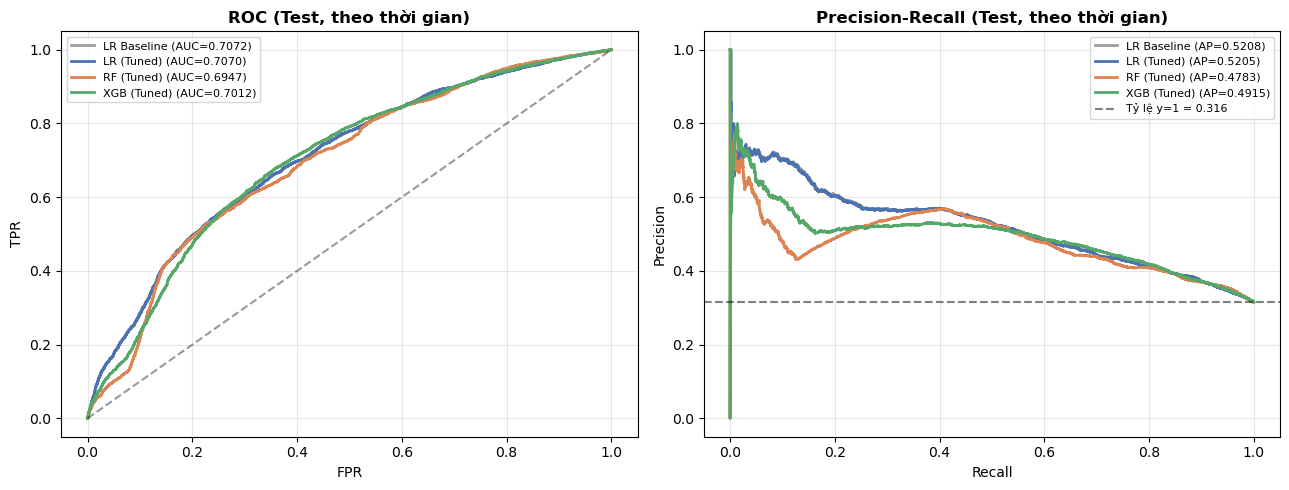

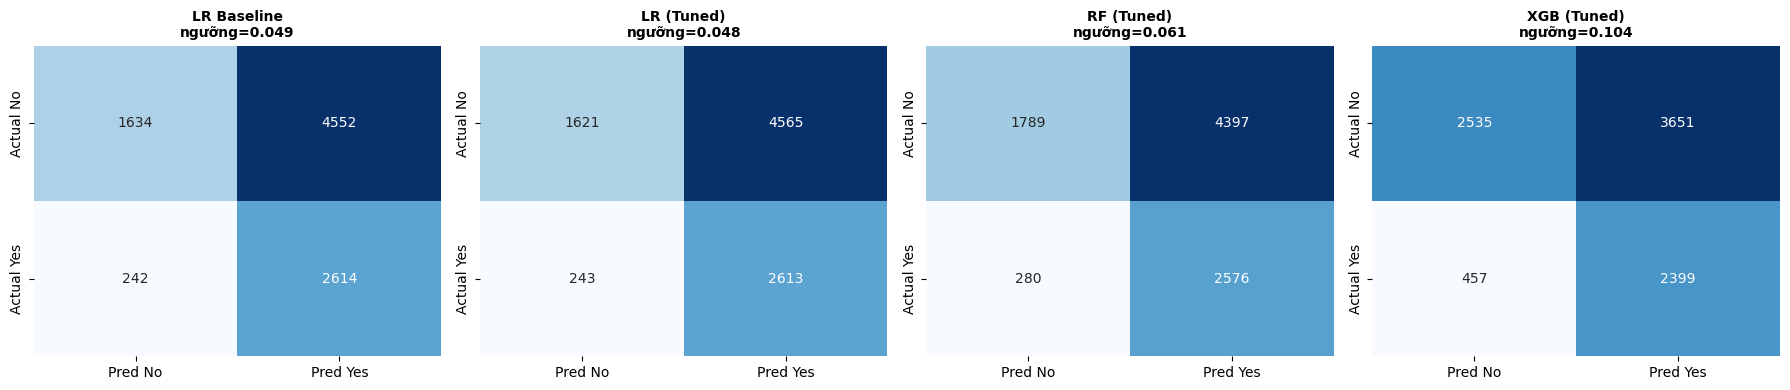

In [22]:
colors = {'LR Baseline': '#9E9E9E', 'LR (Tuned)': '#4C72B0', 'RF (Tuned)': '#DD8452', 'XGB (Tuned)': '#55A868'}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for n, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, p); axes[0].plot(fpr, tpr, color=colors[n], lw=2, label=f'{n} (AUC={roc_auc_score(y_test, p):.4f})')
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, color=colors[n], lw=2, label=f'{n} (AP={average_precision_score(y_test, p):.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR'); axes[0].set_title('ROC (Test, theo thời gian)', fontweight='bold')
axes[1].axhline(y_test.mean(), color='k', ls='--', alpha=0.5, label=f'Tỷ lệ y=1 = {y_test.mean():.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_title('Precision-Recall (Test, theo thời gian)', fontweight='bold')
for a in axes: a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (n, p) in zip(axes, proba_test.items()):
    cm = confusion_matrix(y_test, (p >= thresholds[n]).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=['Pred No', 'Pred Yes'], yticklabels=['Actual No', 'Actual Yes'])
    ax.set_title(f'{n}\nngưỡng={thresholds[n]:.3f}', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.show()

## 12. Feature importance
Hệ số cho Logistic Regression (biến số đã chuẩn hóa), Gini importance cho Random Forest, importance mặc định của XGBoost. Top 15 của mô hình đã tối ưu.

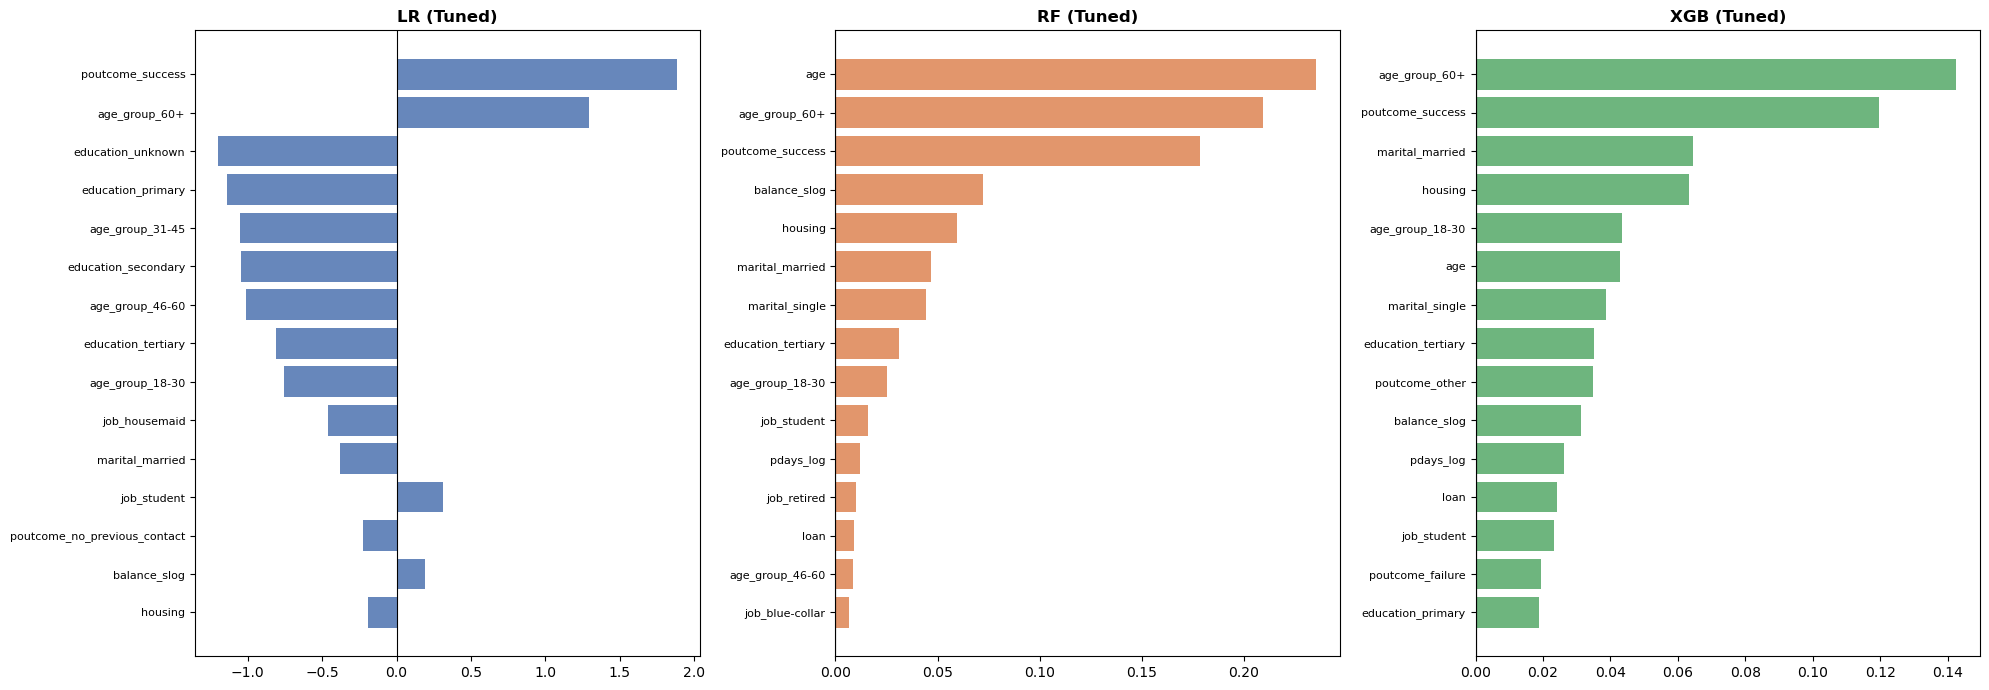

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, name in zip(axes, ['LR (Tuned)', 'RF (Tuned)', 'XGB (Tuned)']):
    pipe = models[name]; names = pipe.named_steps['pre'].get_feature_names_out(); est = pipe.named_steps['model']
    vals = est.coef_[0] if name.startswith('LR') else est.feature_importances_
    imp = pd.Series(vals, index=names).sort_values(key=abs, ascending=False).head(15)
    ax.barh(imp.index, imp.values, color=colors[name], alpha=0.85); ax.invert_yaxis(); ax.axvline(0, color='k', lw=0.8)
    ax.set_title(name, fontweight='bold'); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()

## 13. Mô phỏng vận hành (walk-forward)
### 13.1 Cập nhật ngưỡng định kỳ
Ngưỡng xác suất cố định chọn từ quá khứ sẽ lệch khi tỷ lệ `y=1` đổi. Trong thực tế nhãn của các cuộc gọi cũ có sẵn sau vài ngày, nên có thể cập nhật ngưỡng: chia test thành 4 khối liên tiếp; với khối *k* dùng ngưỡng F1 chọn từ nhãn của khối *k−1* (mô hình giữ nguyên). So sánh với ngưỡng cố định chọn một lần ở mục 8, trên cùng các khối 2–4.

In [24]:
chunks = np.array_split(np.arange(len(y_test)), 4)
p_sel, yt = proba_test[selected], y_test.to_numpy()
fixed_thr = thresholds[selected]
pool = {'fixed': ([], []), 'rolling': ([], [])}
rows = []
for k in range(1, 4):
    prev, cur = chunks[k - 1], chunks[k]
    thr_roll = best_f1_threshold(yt[prev], p_sel[prev])
    for key, thr in [('fixed', fixed_thr), ('rolling', thr_roll)]:
        pool[key][0].append(yt[cur]); pool[key][1].append((p_sel[cur] >= thr).astype(int))
    rows.append({'Khối': k + 1, 'Tỷ lệ y=1': yt[cur].mean(), 'Ngưỡng cố định': fixed_thr, 'Ngưỡng cập nhật': thr_roll})
display(pd.DataFrame(rows).round(3))
wf = {}
for key, (ys, ps) in pool.items():
    ys, ps = np.concatenate(ys), np.concatenate(ps)
    wf['Ngưỡng cố định' if key == 'fixed' else 'Ngưỡng cập nhật'] = {
        'Precision': precision_score(ys, ps, zero_division=0), 'Recall': recall_score(ys, ps), 'F1-Score': f1_score(ys, ps)}
ys_all = np.concatenate(pool['fixed'][0]); pr_all = ys_all.mean()
wf['Gọi tất cả (baseline)'] = {'Precision': pr_all, 'Recall': 1.0, 'F1-Score': 2 * pr_all / (1 + pr_all)}
wf = pd.DataFrame(wf).T
print(f'Mô hình: {selected} — gộp 3 khối cuối của test'); display(wf.round(4))

,Khối,Tỷ lệ y=1,Ngưỡng cố định,Ngưỡng cập nhật
0,2,0.239,0.049,0.055
1,3,0.412,0.049,0.082
2,4,0.530,0.049,0.040


Mô hình: LR Baseline — gộp 3 khối cuối của test


,Precision,Recall,F1-Score
Ngưỡng cố định,0.4150,0.9382,0.5755
Ngưỡng cập nhật,0.4274,0.8703,0.5733
Gọi tất cả (baseline),0.3935,1.0000,0.5647


### 13.2 Huấn luyện lại định kỳ — quy trình triển khai khuyến nghị
Đây là phần cải thiện lớn nhất trong thử nghiệm: dữ liệu trôi theo thời gian nên mô hình "đóng băng" xuống cấp dần, còn huấn luyện lại khi có nhãn mới giúp bắt kịp phân phối mới.

Ở 13.1 mô hình bị "đóng băng" sau khi huấn luyện trên train. Trong thực tế có thể **huấn luyện lại** khi có nhãn mới. Ở đây với mỗi khối *k* của test, mô hình được fit lại trên **toàn bộ dữ liệu có nhãn trước khối đó** (train + các khối test trước), rồi dự đoán khối *k*. Việc cân bằng lớp (`class_weight='balanced'`, Balanced RF) được tính lại trên dữ liệu của mỗi lần fit nên tự cập nhật theo phân phối mới. Tham số vẫn là tham số đã tối ưu chỉ trên train nên không rò rỉ; giả định nhãn của các cuộc gọi cũ đã có khi cần. Khối 1 chính là mô hình đóng băng (chưa có dữ liệu mới) nên so sánh ở các khối 2–4.

In [25]:
rt_blocks = np.array_split(np.arange(n_train, len(df)), 4)
rt_rows = []
for k, blk in enumerate(rt_blocks):
    yb = y_all.iloc[blk].to_numpy()
    for n in models:
        frozen = proba_test[n][blk - n_train]
        refit  = clone(models[n]).fit(X_all.iloc[:blk[0]], y_all.iloc[:blk[0]]).predict_proba(X_all.iloc[blk])[:, 1]
        rt_rows.append({'Khối': k + 1, 'Mô hình': n, 'Tỷ lệ y=1': yb.mean(),
                        'AUC đóng băng': roc_auc_score(yb, frozen), 'AUC huấn luyện lại': roc_auc_score(yb, refit),
                        'Lift@20% đóng băng': topk_metrics(yb, frozen, 0.2)['Lift'],
                        'Lift@20% huấn luyện lại': topk_metrics(yb, refit, 0.2)['Lift']})
rt = pd.DataFrame(rt_rows)
print('Chi tiết theo khối:'); display(rt.round(3))
rt_sum = rt[rt['Khối'] >= 2].groupby('Mô hình')[['AUC đóng băng', 'AUC huấn luyện lại', 'Lift@20% đóng băng', 'Lift@20% huấn luyện lại']].mean()
rt_sum['Δ AUC'] = rt_sum['AUC huấn luyện lại'] - rt_sum['AUC đóng băng']
rt_sum['Δ Lift@20%'] = rt_sum['Lift@20% huấn luyện lại'] - rt_sum['Lift@20% đóng băng']
print('Trung bình các khối 2–4:'); display(rt_sum.round(4))

Chi tiết theo khối:


,Khối,Mô hình,Tỷ lệ y=1,AUC đóng băng,AUC huấn luyện lại,Lift@20% đóng băng,Lift@20% huấn luyện lại
0,1,LR Baseline,0.083,0.557,0.557,1.224,1.224
1,1,LR (Tuned),0.083,0.557,0.557,1.251,1.251
2,1,RF (Tuned),0.083,0.588,0.588,1.357,1.357
3,1,XGB (Tuned),0.083,0.589,0.589,1.437,1.437
4,2,LR Baseline,0.239,0.644,0.639,1.640,1.630
5,2,LR (Tuned),0.239,0.644,0.639,1.621,1.630
6,2,RF (Tuned),0.239,0.628,0.623,1.658,1.640
7,2,XGB (Tuned),0.239,0.645,0.640,1.658,1.640
8,3,LR Baseline,0.412,0.570,0.578,1.230,1.364
9,3,LR (Tuned),0.412,0.570,0.577,1.214,1.348


Trung bình các khối 2–4:


,AUC đóng băng,AUC huấn luyện lại,Lift@20% đóng băng,Lift@20% huấn luyện lại,Δ AUC,Δ Lift@20%
Mô hình,,,,,,
LR (Tuned),0.6202,0.6238,1.3877,1.4871,0.0036,0.0994
LR Baseline,0.6203,0.6237,1.4007,1.4911,0.0034,0.0904
RF (Tuned),0.6011,0.6104,1.2236,1.4036,0.0094,0.1800
XGB (Tuned),0.6052,0.6227,1.2799,1.4611,0.0175,0.1812


### 13.2b Tự động cập nhật ngưỡng F1 sau mỗi lần huấn luyện lại
Sau mỗi lần huấn luyện lại, phân phối xác suất đầu ra của mô hình đổi (và tỷ lệ `y=1` cũng đổi), nên ngưỡng cũ ở mục 8 không còn khớp. Với mỗi khối *k* của test (khối 2–4):
1. fit lại trên toàn bộ dữ liệu có nhãn **trước** khối *k*;
2. tính xác suất out-of-fold của chính dữ liệu lũy kế đó bằng `TimeSeriesSplit`;
3. chọn ngưỡng F1 từ OOF của 2 fold gần nhất (cùng quy tắc ở mục 8, hàm `best_f1_threshold`);
4. áp ngưỡng mới cho khối *k*. Không dùng nhãn của khối *k* nên không rò rỉ.

So 3 chính sách trên cùng các khối: mô hình đóng băng với ngưỡng cố định, mô hình huấn luyện lại nhưng giữ ngưỡng cũ, và mô hình huấn luyện lại với ngưỡng cập nhật; kèm baseline "gọi tất cả". Chỉ chạy cho LR Baseline và mô hình được chọn để tiết kiệm thời gian.

In [26]:
pol_rows, thr_rows = [], []
for name in dict.fromkeys(['LR Baseline', selected]):
    pooled = {'Đóng băng + ngưỡng cố định': ([], []), 'Huấn luyện lại + ngưỡng cũ': ([], []),
              'Huấn luyện lại + ngưỡng cập nhật (OOF)': ([], [])}
    for k, blk in enumerate(rt_blocks):
        if k == 0:
            continue                      # khối 1: chưa có nhãn mới nên trùng mô hình đóng băng
        Xc, yc = X_all.iloc[:blk[0]], y_all.iloc[:blk[0]]
        yb = y_all.iloc[blk].to_numpy()
        oof = cv_time(models[name], Xc, yc)['oof']
        last2 = np.concatenate([va for _, va in list(tscv.split(Xc))[-2:]])
        thr_new = best_f1_threshold(yc.iloc[last2], oof[last2])
        refit_p = clone(models[name]).fit(Xc, yc).predict_proba(X_all.iloc[blk])[:, 1]
        frozen_p = proba_test[name][blk - n_train]
        for key, (p_, t_) in {'Đóng băng + ngưỡng cố định': (frozen_p, thresholds[name]),
                              'Huấn luyện lại + ngưỡng cũ': (refit_p, thresholds[name]),
                              'Huấn luyện lại + ngưỡng cập nhật (OOF)': (refit_p, thr_new)}.items():
            pooled[key][0].append(yb); pooled[key][1].append((p_ >= t_).astype(int))
        thr_rows.append({'Mô hình': name, 'Khối': k + 1, 'Tỷ lệ y=1': yb.mean(),
                         'Ngưỡng cũ (mục 8)': thresholds[name], 'Ngưỡng cập nhật (OOF)': thr_new})
    for key, (ys, ps) in pooled.items():
        ys, ps = np.concatenate(ys), np.concatenate(ps)
        pol_rows.append({'Mô hình': name, 'Chính sách': key, 'Precision': precision_score(ys, ps, zero_division=0),
                         'Recall': recall_score(ys, ps), 'F1': f1_score(ys, ps)})
    pr_ = ys.mean()
    pol_rows.append({'Mô hình': name, 'Chính sách': 'Gọi tất cả (baseline)', 'Precision': pr_, 'Recall': 1.0, 'F1': 2 * pr_ / (1 + pr_)})
print('Ngưỡng theo từng khối:'); display(pd.DataFrame(thr_rows).round(3))
pol_tbl = pd.DataFrame(pol_rows).set_index(['Mô hình', 'Chính sách'])
print('Gộp khối 2–4:'); display(pol_tbl.round(4))

Ngưỡng theo từng khối:


,Mô hình,Khối,Tỷ lệ y=1,Ngưỡng cũ (mục 8),Ngưỡng cập nhật (OOF)
0,LR Baseline,2,0.239,0.049,0.069
1,LR Baseline,3,0.412,0.049,0.076
2,LR Baseline,4,0.530,0.049,0.075


Gộp khối 2–4:


Precision  Recall      F1
Mô hình     Chính sách                                                       
LR Baseline Đóng băng + ngưỡng cố định                 0.4150  0.9382  0.5755
            Huấn luyện lại + ngưỡng cũ                 0.4107  0.9685  0.5769
            Huấn luyện lại + ngưỡng cập nhật (OOF)     0.4403  0.8722  0.5852
            Gọi tất cả (baseline)                      0.3935  1.0000  0.5647

### 13.3 Mô hình được chọn: đóng băng và huấn luyện lại theo từng khối
Tóm tắt cho mô hình được chọn ở mục 8 (kèm baseline để đối chiếu): AUC và Lift@20% trong từng khối khi mô hình đóng băng so với khi huấn luyện lại trước mỗi khối.

In [27]:
show = list(dict.fromkeys(['LR Baseline', selected]))
sel_tbl = rt[rt['Mô hình'].isin(show)][['Mô hình', 'Khối', 'Tỷ lệ y=1', 'AUC đóng băng', 'AUC huấn luyện lại', 'Lift@20% đóng băng', 'Lift@20% huấn luyện lại']]
display(sel_tbl.round(3).reset_index(drop=True))

,Mô hình,Khối,Tỷ lệ y=1,AUC đóng băng,AUC huấn luyện lại,Lift@20% đóng băng,Lift@20% huấn luyện lại
0,LR Baseline,1,0.083,0.557,0.557,1.224,1.224
1,LR Baseline,2,0.239,0.644,0.639,1.640,1.630
2,LR Baseline,3,0.412,0.570,0.578,1.230,1.364
3,LR Baseline,4,0.530,0.647,0.655,1.332,1.479


## 14. So sánh với cách làm cũ (ablation)
Chạy lại **đúng công thức cũ** (đặc trưng cũ với `pdays → 0`, `month` one-hot `drop='first'`, Optuna `StratifiedKFold` xáo trộn tối ưu PR-AUC, ngưỡng từ OOF xáo trộn) nhưng huấn luyện/tuning chỉ trên cùng tập train theo thời gian, rồi đánh giá trên **cùng test theo thời gian**. Chỉ làm với XGBoost, số trial `N_TRIALS_OLD`. Mục đích: tách riêng phần cải thiện do sửa quy trình.

In [28]:
def old_features(d):
    X = d.drop(columns=['y', 'day', 'duration']).copy()
    X['was_contacted_before'] = (X['pdays'] != -1).astype(int)
    X['pdays'] = X['pdays'].replace(-1, 0)
    for c in ['default', 'housing', 'loan']:
        X[c] = X[c].map({'yes': 1, 'no': 0})
    return X

def old_pipe(model):
    cat = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
    num = ['age', 'balance', 'campaign', 'pdays', 'previous']
    pre = ColumnTransformer([('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat),
                             ('num', 'passthrough', num)], remainder='passthrough', verbose_feature_names_out=False)
    return Pipeline([('pre', pre), ('model', model)])

Xo_tr, Xo_te = old_features(train_df), old_features(test_df)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def objective_old(trial):
    p = {'n_estimators': trial.suggest_int('n_estimators', 100, 500), 'max_depth': trial.suggest_int('max_depth', 3, 10),
         'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.3, log=True), 'subsample': trial.suggest_float('subsample', 0.5, 1.0),
         'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0), 'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
         'gamma': trial.suggest_float('gamma', 0.0, 5.0), 'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
         'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True)}
    sc = []
    for tr, va in skf.split(Xo_tr, y_train):
        m = old_pipe(XGBClassifier(**p, eval_metric='logloss', tree_method='hist', random_state=RANDOM_STATE, n_jobs=1, verbosity=0)).fit(Xo_tr.iloc[tr], y_train.iloc[tr])
        sc.append(average_precision_score(y_train.iloc[va], m.predict_proba(Xo_tr.iloc[va])[:, 1]))
    return float(np.mean(sc))

study_old = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_old.optimize(objective_old, n_trials=N_TRIALS_OLD)
mk_old = lambda: old_pipe(XGBClassifier(**study_old.best_params, eval_metric='logloss', tree_method='hist', random_state=RANDOM_STATE, n_jobs=-1, verbosity=0))

oof_old = np.zeros(len(y_train))
for tr, va in skf.split(Xo_tr, y_train):
    oof_old[va] = mk_old().fit(Xo_tr.iloc[tr], y_train.iloc[tr]).predict_proba(Xo_tr.iloc[va])[:, 1]
thr_old = best_f1_threshold(y_train, oof_old)
p_old = mk_old().fit(Xo_tr, y_train).predict_proba(Xo_te)[:, 1]

cmp_rows = {
    'XGB — cách cũ (CV xáo trộn, PR-AUC, ngưỡng OOF xáo trộn)': {'Ngưỡng': thr_old, **metrics_at(y_test, p_old, thr_old),
                                                               'F1 tham chiếu (oracle)': f1_score(y_test, (p_old >= best_f1_threshold(y_test, p_old)).astype(int))},
    'XGB — cách mới (TimeSeriesSplit, pdays/month xử lý lại, scale_pos_weight)': {'Ngưỡng': thresholds['XGB (Tuned)'], **metrics_at(y_test, proba_test['XGB (Tuned)'], thresholds['XGB (Tuned)']),
                                                                              'F1 tham chiếu (oracle)': oracle['XGB (Tuned)']},
}
display(pd.DataFrame(cmp_rows).T.round(4))

,Ngưỡng,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,F1 tham chiếu (oracle)
"XGB — cách cũ (CV xáo trộn, PR-AUC, ngưỡng OOF xáo trộn)",0.1356,0.6701,0.4832,0.638,0.5499,0.6936,0.4735,0.5567
"XGB — cách mới (TimeSeriesSplit, pdays/month xử lý lại, scale_pos_weight)",0.1044,0.5457,0.3965,0.840,0.5387,0.7012,0.4915,0.5541


## 15. Phụ lục: ảnh hưởng của `duration`
`duration` chỉ biết sau khi cuộc gọi kết thúc nên không dùng được khi dự đoán *trước* cuộc gọi. Huấn luyện lại cùng mô hình (cùng tham số đã tối ưu, cùng chia theo thời gian) **có thêm `duration`** để đo mức chênh lệch. Kết quả có `duration` chỉ là cận trên tham khảo.

In [29]:
X_dur = build_features(df, MONTH_MODE, DROP_CONTACT, use_duration=True)
rows = {}
for name, pipe in make_models(X_dur.iloc[:n_train]).items():
    pipe.fit(X_dur.iloc[:n_train], y_train)
    p = pipe.predict_proba(X_dur.iloc[n_train:])[:, 1]
    rows[name] = {'ROC-AUC (có duration)': roc_auc_score(y_test, p), 'PR-AUC (có duration)': average_precision_score(y_test, p)}
dur_tbl = pd.DataFrame(rows).T
dur_tbl['ROC-AUC (không duration)'] = tbl_05['ROC-AUC']; dur_tbl['PR-AUC (không duration)'] = tbl_05['PR-AUC']
dur_tbl['Δ ROC-AUC'] = dur_tbl['ROC-AUC (có duration)'] - dur_tbl['ROC-AUC (không duration)']
dur_tbl.round(4)

,ROC-AUC (có duration),PR-AUC (có duration),ROC-AUC (không duration),PR-AUC (không duration),Δ ROC-AUC
LR Baseline,0.8190,0.6161,0.7072,0.5208,0.1119
LR (Tuned),0.8186,0.6154,0.7070,0.5205,0.1117
RF (Tuned),0.7554,0.5420,0.6947,0.4783,0.0607
XGB (Tuned),0.8015,0.5855,0.7012,0.4915,0.1003


## 16. Kiểm tra rò rỉ và kết luận
### Quy trình triển khai khuyến nghị
1. **Chọn mô hình** bằng so sánh cặp theo fold với baseline (mục 8); nếu không có mô hình phức tạp nào vượt rõ ràng thì dùng Logistic Regression đơn giản.
2. **Huấn luyện lại định kỳ**: mỗi khi có thêm khối nhãn mới (mục 13.2), fit lại trên toàn bộ dữ liệu có nhãn đến thời điểm đó, giữ nguyên tham số đã tối ưu.
3. **Vận hành theo ngân sách**: gọi top-k% khách có điểm cao nhất (Lift@k, mục 9) thay vì dựa vào một ngưỡng xác suất cố định, vì tỷ lệ `y=1` trôi theo thời gian.
4. **Giám sát**: theo dõi AUC và Lift theo từng khối thời gian mới; nếu AUC theo khối giảm rõ rệt thì kiểm tra lại concept drift (mục 3.1).
5. **Báo cáo trung thực**: dùng AUC/Lift theo khối làm con số chính, AUC gộp toàn test chỉ là thông tin phụ.

### Kiểm tra rò rỉ tự động và kết luận
Cell `assert` kiểm tra các điều kiện chống rò rỉ: train đứng trước test theo thời gian; trong mỗi fold CV, train đứng trước validation; không có `duration`, `day`, `y` hay chỉ số thời gian trong ma trận đặc trưng; `campaign_log` bị bỏ khi `DROP_CAMPAIGN = True`; tháng chỉ giảm ở bước 12 sang 1 và ngày không giảm trong cùng tháng. Phần còn lại in kết luận sinh tự động từ các kết quả ở trên, nên số liệu luôn khớp với lần chạy.

In [30]:
# --- Kiểm tra tự động ---
assert train_df.index.max() < test_df.index.min()
assert all(tr.max() < va.min() for tr, va in tscv.split(X_train)), 'Trong CV, train fold phải đứng trước validation fold'
assert not DROP_CAMPAIGN or 'campaign_log' not in X_all.columns
assert 'duration' not in X_all.columns and 'day' not in X_all.columns and 'y' not in X_all.columns
assert 'month_idx' not in X_all.columns and 'nam_idx' not in X_all.columns, 'Không đưa chỉ số thời gian vào mô hình'
assert set(zip(m_num[:-1][np.diff(m_num) < 0], m_num[1:][np.diff(m_num) < 0])) <= {(12, 1)}, 'Tháng chỉ được giảm ở 12 -> 1'
assert not ((np.diff(m_num) == 0) & (np.diff(df['day'].to_numpy()) < 0)).any(), 'Ngày phải không giảm trong cùng tháng'
print('Các kiểm tra rò rỉ đều đạt.')

best = selected
print('=' * 72); print('KẾT LUẬN'); print('=' * 72)
print(f'Cấu hình đặc trưng (chọn bằng CV thời gian): month={MONTH_MODE}, drop_contact={DROP_CONTACT}')
print(f'Mô hình được chọn theo CV thời gian (không dùng test): {best}')
print(f'  CV ROC-AUC (có trọng số): {cv_auc[best]:.4f}')
print(f'  [Thước đo chính] AUC TB theo khối thời gian (đóng băng): {headline.loc[best, "AUC TB theo khối"]:.4f} (thấp nhất {headline.loc[best, "AUC thấp nhất"]:.4f}) | Lift@20% TB theo khối: {headline.loc[best, "Lift@20% TB theo khối"]:.2f}x')
print(f'  [Phụ] AUC gộp toàn test: {headline.loc[best, "AUC gộp toàn test (phụ)"]:.4f} | PR-AUC gộp: {tbl_05.loc[best, "PR-AUC"]:.4f} (tỷ lệ y=1 trong test: {y_test.mean():.3f}); lạc quan hơn vì gộp các khối có tỷ lệ y=1 rất khác nhau')
print(f'  So với LR Baseline: ΔCV AUC = {cv_auc[best] - cv_auc["LR Baseline"]:+.4f} | ΔAUC TB theo khối = {headline.loc[best, "AUC TB theo khối"] - headline.loc["LR Baseline", "AUC TB theo khối"]:+.4f}')
print(f'  Ngưỡng cố định {thresholds[best]:.3f}: Precision={tbl_thr.loc[best, "Precision"]:.4f}, Recall={tbl_thr.loc[best, "Recall"]:.4f}, F1={tbl_thr.loc[best, "F1-Score"]:.4f} (F1 oracle tham chiếu: {oracle[best]:.4f})')
print(f'  Huấn luyện lại định kỳ (khối 2-4): AUC {rt_sum.loc[best, "AUC huấn luyện lại"]:.4f} so với đóng băng {rt_sum.loc[best, "AUC đóng băng"]:.4f} | Lift@20% {rt_sum.loc[best, "Lift@20% huấn luyện lại"]:.2f}x so với {rt_sum.loc[best, "Lift@20% đóng băng"]:.2f}x')
print(f'  Ngưỡng cập nhật định kỳ (khối 2-4): F1={wf.loc["Ngưỡng cập nhật", "F1-Score"]:.4f} so với cố định {wf.loc["Ngưỡng cố định", "F1-Score"]:.4f}')
_p = pol_tbl.loc[best]
print(f'  Sau huấn luyện lại (khối 2-4): F1 ngưỡng cũ {_p.loc["Huấn luyện lại + ngưỡng cũ", "F1"]:.4f} → ngưỡng cập nhật OOF {_p.loc["Huấn luyện lại + ngưỡng cập nhật (OOF)", "F1"]:.4f} (gọi tất cả: {_p.loc["Gọi tất cả (baseline)", "F1"]:.4f})')
old_k = 'XGB — cách cũ (CV xáo trộn, PR-AUC, ngưỡng OOF xáo trộn)'; new_k = 'XGB — cách mới (TimeSeriesSplit, pdays/month xử lý lại, scale_pos_weight)'
print(f'  XGB cách cũ → mới trên cùng test thời gian: ROC-AUC {cmp_rows[old_k]["ROC-AUC"]:.4f} → {cmp_rows[new_k]["ROC-AUC"]:.4f}, F1 {cmp_rows[old_k]["F1-Score"]:.4f} → {cmp_rows[new_k]["F1-Score"]:.4f}')
print(f'  ROC-AUC khi thêm duration (cận trên, không dùng được thực tế): {dur_tbl.loc[best, "ROC-AUC (có duration)"]:.4f}')
print('=' * 72)

Các kiểm tra rò rỉ đều đạt.
KẾT LUẬN
Cấu hình đặc trưng (chọn bằng CV thời gian): month=none, drop_contact=True
Mô hình được chọn theo CV thời gian (không dùng test): LR Baseline
  CV ROC-AUC (có trọng số): 0.5852
  [Thước đo chính] AUC TB theo khối thời gian (đóng băng): 0.6045 (thấp nhất 0.5570) | Lift@20% TB theo khối: 1.36x
  [Phụ] AUC gộp toàn test: 0.7072 | PR-AUC gộp: 0.5208 (tỷ lệ y=1 trong test: 0.316); lạc quan hơn vì gộp các khối có tỷ lệ y=1 rất khác nhau
  So với LR Baseline: ΔCV AUC = +0.0000 | ΔAUC TB theo khối = +0.0000
  Ngưỡng cố định 0.049: Precision=0.3648, Recall=0.9153, F1=0.5217 (F1 oracle tham chiếu: 0.5473)
  Huấn luyện lại định kỳ (khối 2-4): AUC 0.6237 so với đóng băng 0.6203 | Lift@20% 1.49x so với 1.40x
  Ngưỡng cập nhật định kỳ (khối 2-4): F1=0.5733 so với cố định 0.5755
  Sau huấn luyện lại (khối 2-4): F1 ngưỡng cũ 0.5769 → ngưỡng cập nhật OOF 0.5852 (gọi tất cả: 0.5647)
  XGB cách cũ → mới trên cùng test thời gian: ROC-AUC 0.6936 → 0.7012, F1 0.5499 → 0.